# Imports

In [ ]:
import pulp
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import truncnorm

# Loading Data

In [6]:
data_dir = r"..\data\ToyCar_StudentProject.xlsx"

In [7]:
equipements = pd.read_excel(data_dir, "Equipements", index_col=0)
generic = pd.read_excel(data_dir, "Generic", index_col=0)
operations = pd.read_excel(data_dir, "Operations", index_col="Operation")

In [ ]:
# equipements
equipement_id = equipements.index.to_list()
category = equipements['Category']
supplier = equipements['Supplier']
if 'Age' in equipements.columns:
    age = equipements['Age']
speed_factor = equipements['Speed factor']
purshasing_cost = equipements['Purchasing cost']
operation_cost = equipements['Operation cost']
salvage_cost = equipements['Salvage cost ']
# generic
takt = generic[generic.index=="Takt"]['Value'].values
horizon = generic[generic.index=="Horizon"]['Value'].values
lost_sale_penalty = generic[generic.index=="LostSalePenalty"]['Value'].values
years = [i+1 for i in range(10)]
duration_year_seconds = 24*3600*365
# operations
resource_group = operations['Resource Group'].unique()
operation = operations.index.unique().to_list()
duration_operation_year = operations.iloc[:, 1:].values

# Modeling

In [41]:
problem = pulp.LpProblem("Assembly Line", sense=pulp.LpMinimize)

# variables
X = pulp.LpVariable.dicts("X", (equipement_id, resource_group, years), cat="Integer", lowBound=0)
Y = pulp.LpVariable.dicts("Y", equipement_id, cat="Integer", lowBound=0)
F = pulp.LpVariable.dicts("F", (resource_group, years), cat="Continuous", lowBound=0)
M = pulp.LpVariable.dicts("M", years, cat="Continuous", lowBound=0)

# objective function
problem += (
    pulp.lpSum([Y[e] * purshasing_cost[e] for e in equipement_id]) +
    pulp.lpSum([X[e][g][y] * operation_cost[e] for e in equipement_id for g in resource_group for y in years]) -
    pulp.lpSum([Y[e] * salvage_cost[e] for e in equipement_id ]) +
    pulp.lpSum([M[y] * duration_year_seconds * lost_sale_penalty[0] for y in years])
)

# constraints
for g in resource_group:
    for year_index, y in enumerate(years):
        mask = (operations["Resource Group"] == g)
        indices = np.where(mask)[0]
        total = duration_operation_year[indices, year_index].sum()
        if total!=0:
            problem += F[g][y] == pulp.lpSum([X[e][g][y]*speed_factor[e] for e in equipement_id])/total
        else:
            problem += F[g][y] == 0
for y in years:
    for e in equipement_id:
        problem+= pulp.lpSum([X[e][g][y] for g in resource_group]) <= Y[e]

for g in resource_group:
    for y in years:
        problem += M[y] >= (1/takt[0]) - F[g][y]

c:\Users\MOHAMED\.virtualenvs\env_ro_py\Lib\site-packages\pulp\pulp.py:1706: UserWarning: Spaces are not permitted in the name. Converted to '_'
  warnings.warn("Spaces are not permitted in the name. Converted to '_'")


# Solving the Problem

In [42]:
solver = pulp.GUROBI_CMD()
problem.solve()
problem.solve(solver)
print(f"Problem status: {problem.status}")
for var in problem.variables():
    print(f" {var.name}: {var.value()}")

print(f"Objective function: {problem.objective.value()}")

Problem status: 1
 F_A_1: 0.1170731707315
 F_A_10: 0.11519999999999998
 F_A_2: 0.1161290322582
 F_A_3: 0.1060773480664
 F_A_4: 0.1170731707315
 F_A_5: 0.1010526315788
 F_A_6: 0.1116279069765
 F_A_7: 0.12060301507549999
 F_A_8: 0.1192546583852
 F_A_9: 0.1288590604028
 F_B_1: 0.16
 F_B_10: 0.1
 F_B_2: 0.15
 F_B_3: 0.15
 F_B_4: 0.104347826087
 F_B_5: 0.11250000000000002
 F_B_6: 0.1263157894736
 F_B_7: 0.11428571428571428
 F_B_8: 0.104347826087
 F_B_9: 0.12857142857142856
 F_C_1: 0.16
 F_C_10: 0.1
 F_C_2: 0.109090909091
 F_C_3: 0.12467532467540002
 F_C_4: 0.1263157894736
 F_C_5: 0.123076923077
 F_C_6: 0.1263157894737
 F_C_7: 0.12000000000000001
 F_C_8: 0.1156626506024
 F_C_9: 0.1129411764706
 F_D_1: 0.24
 F_D_10: 0.11428571428571428
 F_D_2: 0.2
 F_D_3: 0.3
 F_D_4: 0.218181818182
 F_D_5: 0.15
 F_D_6: 0.184615384615
 F_D_7: 0.17142857142857143
 F_D_8: 0.15
 F_D_9: 0.11428571428571428
 F_E_1: 0.137142857143
 F_E_10: 0.11428571428571428
 F_E_2: 0.184615384615
 F_E_3: 0.17777777777777778
 F_E_4

# Visualisation

In [43]:
sns.set_theme(style="whitegrid")

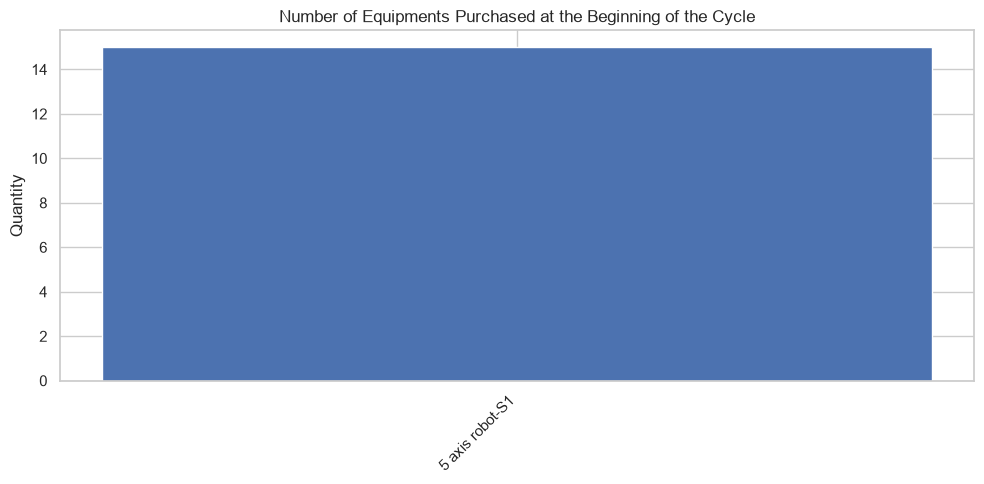

In [44]:
y_data = {e: Y[e].varValue for e in equipement_id if Y[e].varValue and Y[e].varValue > 0}

plt.figure(figsize=(10, 5))
plt.bar(y_data.keys(), y_data.values(), color='#4C72B0')
plt.title("Number of Equipments Purchased at the Beginning of the Cycle")
plt.ylabel("Quantity")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

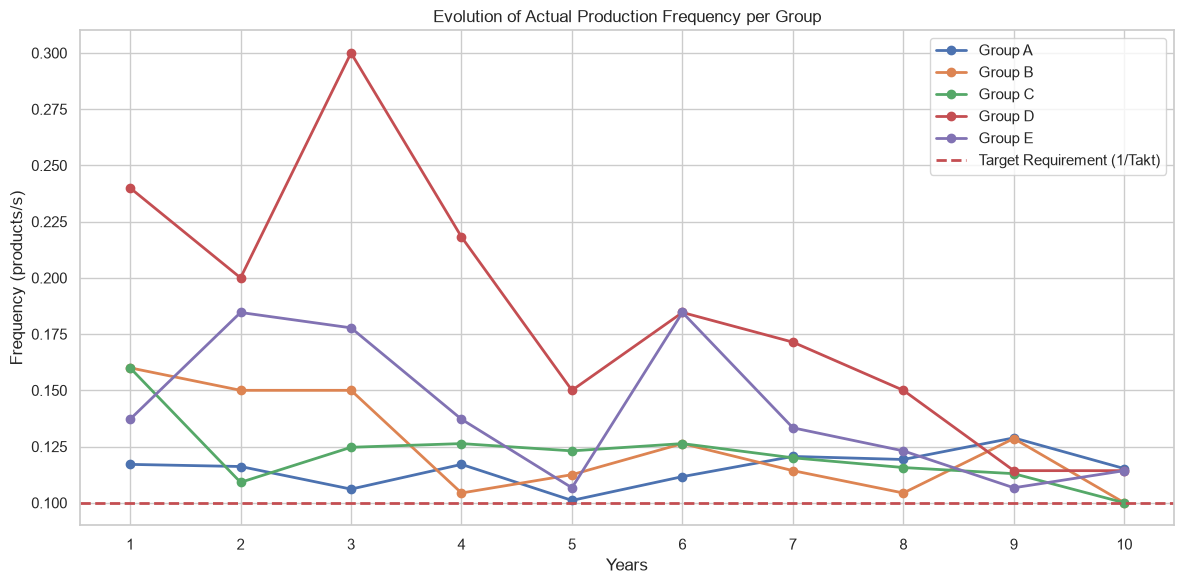

In [45]:
plt.figure(figsize=(12, 6))
target_freq = 1 / takt[0]

for g in resource_group:
    f_vals = [F[g][y].varValue for y in years]
    plt.plot(years, f_vals, marker='o', linewidth=2, label=f'Group {g}')

plt.axhline(y=target_freq, color='#C44E52', linestyle='--', linewidth=2, label='Target Requirement (1/Takt)')
plt.title("Evolution of Actual Production Frequency per Group")
plt.xlabel("Years")
plt.ylabel("Frequency (products/s)")
plt.xticks(years)
plt.legend()
plt.tight_layout()
plt.show()

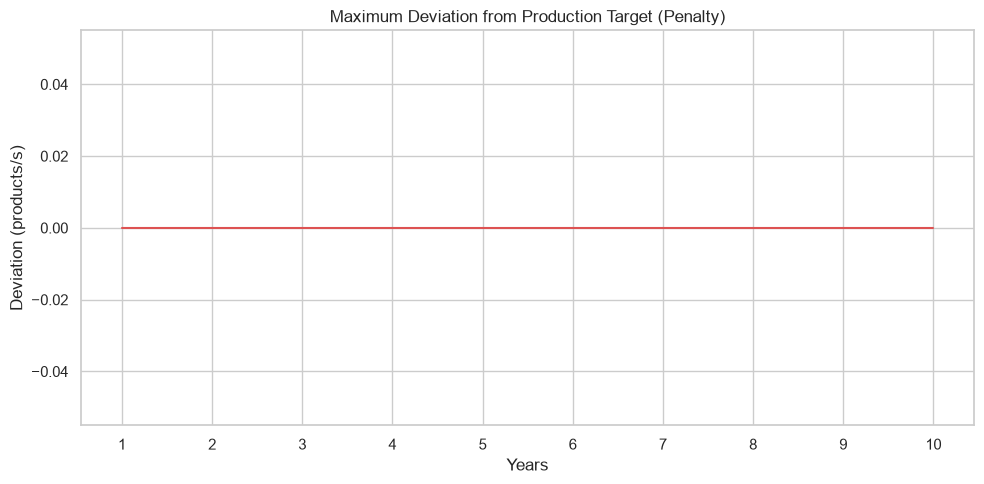

In [46]:
m_vals = [M[y].varValue for y in years]

plt.figure(figsize=(10, 5))
plt.plot(years, m_vals, color="#DD5252")
plt.title("Maximum Deviation from Production Target (Penalty)")
plt.xlabel("Years")
plt.ylabel("Deviation (products/s)")
plt.xticks(years)
plt.tight_layout()
plt.show()